In [1]:
from preprocess_data import Custom_Dataset, ChannelMNISTDataset
from torch.utils.data import DataLoader
import torch
from model import BaseConvModel, ProtoModel, FinalLayer, WholeModel, exp_var_dict

from push_prototypes import push
import h5py
from receptive_field import compute_rf, output_to_input
import matplotlib.pyplot as plt
import numpy as np
import argparse
import matplotlib.patches as patches
import cartopy.crs as ccrs
import cartopy.mpl.ticker as cticker
from cartopy.util import add_cyclic_point
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import torch.optim.lr_scheduler as lr_scheduler
from torchgeo_euro import EuroSAT, ScaleAndNormalize
from torchvision.transforms import v2 as transforms

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

import pickle

import statistics
from statistics import mode

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns


/users/anaray34/.local/lib/python3.11/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: 'Could not load this library: /oscar/home/anaray34/.local/lib/python3.11/site-packages/torchvision/image.so'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(


In [2]:
if torch.cuda.is_available():
    torch.set_default_device('cuda')
    torch.set_default_tensor_type(torch.cuda.FloatTensor)
    device = torch.device('cuda')
    print("GPU is set as the default device.")
else:
    print("CUDA is not available. CPU will be used as the default device.")
    device = 'cpu'

GPU is set as the default device.


/users/anaray34/.local/lib/python3.11/site-packages/torch/__init__.py:1305: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at /pytorch/torch/csrc/tensor/python_tensor.cpp:434.)
  _C._set_default_tensor_type(t)


In [3]:
prototype_info = 'mnist_models/mnist_prototype_info'
model_name = 'mnist_models/mnist_model.pth'

In [4]:
exp_dataset = exp_var_dict['exp_dataset']
whole = WholeModel(exp_dataset, exp_var_dict['num_channels'])
whole.load_state_dict(torch.load(model_name))
with open(prototype_info, "rb") as fp:  
    prototype_info_list = pickle.load(fp)

In [5]:
input_size = (32, 1, 56, 56)
chan_rf = []

for chan in range(exp_var_dict['num_channels']):
    imin_chan, imax_chan, jmin_chan, jmax_chan = compute_rf(whole.base_list[0], whole.proto_list[chan],input_size, prototype_info_list[chan][-1])
    chan_rf.append([imin_chan, imax_chan, jmin_chan, jmax_chan])

GPU is set as the default device.
GPU is set as the default device.
GPU is set as the default device.


In [6]:

train_data = ChannelMNISTDataset(hdf5_data_file='/oscar/home/anaray34/data/anaray34/data/syntheticMNIST/synthetic_data_channelmnist.hdf5', im_name='train_images',label_name='train_labels')
val_data = ChannelMNISTDataset(hdf5_data_file='/oscar/home/anaray34/data/anaray34/data/syntheticMNIST/synthetic_data_channelmnist.hdf5', im_name='val_images',label_name='val_labels')
test_data = ChannelMNISTDataset(hdf5_data_file='/oscar/home/anaray34/data/anaray34/data/syntheticMNIST/synthetic_data_channelmnist.hdf5', im_name='test_images',label_name='test_labels')

with h5py.File("/oscar/home/anaray34/data/anaray34/data/syntheticMNIST/synthetic_data_channelmnist.hdf5",'r') as f:
    all_images = f['train_images'][:]
    all_labels = f['train_labels'][:]
    test_images = f['test_images'][:]
    test_labels = f['test_labels'][:]
    

train_dataloader = DataLoader(train_data, batch_size = exp_var_dict['batch_size'])
val_dataloader = DataLoader(val_data)
test_dataloader = DataLoader(test_data, shuffle=False)

push_dataloader = DataLoader(train_data, batch_size = len(all_images), shuffle=False)
print(len(train_data))
print(len(val_data))
print(len(test_data))

print(np.unique(test_labels, return_counts=True))


8640
2160
1200
(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([131, 123, 122, 126, 106, 112, 109, 119, 126, 126]))


/users/anaray34/.local/lib/python3.11/site-packages/torch/utils/_device.py:109: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return func(*args, **kwargs)


Testing accuracy: 0.9783333333333334


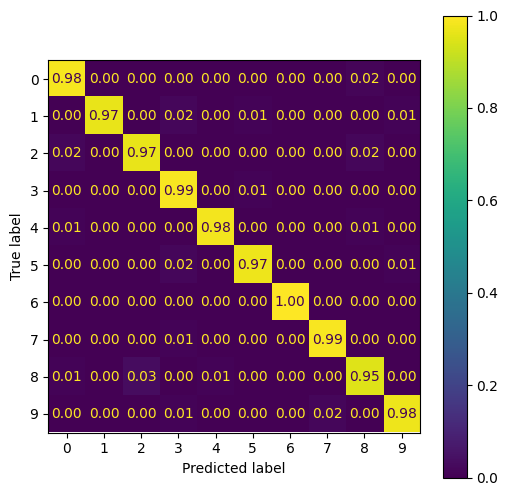

In [7]:
epoch_cross_entropy = 0
n_examples = 0
n_correct = 0

tp_active = 0
tn_inactive = 0
fp_inact_act = 0
fn_act_inact = 0


correct = []
true_label = []
pred_label = []
index_nums = []
index_num = 0
test_output = []
test_output_probs = []

max_inds_arr_list = []
max_sims_arr_list = []
for inputs, labels in test_dataloader:
    inputs = torch.nan_to_num(inputs)
    whole.base_list[0].eval()
    for chan in range(exp_var_dict['num_channels']):
        whole.proto_list[chan].eval()
    whole.final_list[0].eval()
    with torch.no_grad():
        output, min_dist_list, scaled_sim_list = whole(inputs, False)

        # compute loss
        cross_entropy = torch.nn.functional.cross_entropy(output, labels.to(torch.long))
        test_output.append(output.data)

        probs = torch.nn.functional.softmax(output.data)
        test_output_probs.append(probs)
        predicted = torch.max(probs, 1)
        n_examples += labels.size(0)
        n_correct += torch.eq(predicted[1], labels).sum().item()

        if predicted[1] == 0 and labels != 0:
            fn_act_inact +=1
        if predicted[1] == 0 and labels == 0:
            tn_inactive +=1
        if predicted[1] != 0 and labels != 0:
            tp_active += 1
        if predicted[1] !=0 and labels == 0:
            fp_inact_act +=1

        #epoch_cross_entropy += cross_entropy.item()
        correct.append(torch.eq(predicted[1], labels).sum().item())
        true_label.append(int(labels.cpu().item()))
        pred_label.append(predicted[1].cpu().item())

        index_nums.append(index_num)
        index_num+=1

    max_inds_chan = []
    max_sims_chan = []
    for chan in range(exp_var_dict['num_channels']):
        result1 = [np.unravel_index(np.argmax(r.cpu()), r.cpu().shape) for r in scaled_sim_list[chan][0]]
        max_inds_chan.append(result1[:])

        result1 = [torch.amax(scaled_sim_list[chan], dim=(2,3)).cpu().detach().numpy()]
        max_sims_chan.append(result1[0][0][:])
    max_inds_arr_list.append(max_inds_chan)
    max_sims_arr_list.append(max_sims_chan)


acc = n_correct/n_examples
print('Testing accuracy: ' + str(acc))

cm = confusion_matrix(np.asarray(true_label), np.asarray(pred_label), normalize='true')
fig, ax = plt.subplots(figsize=(6,6))
ax = plt.gca()
disp = ConfusionMatrixDisplay(cm)
disp.plot(ax=ax,values_format='.2f')

fig.canvas.draw()  



all_loc_scale = []
all_conv_prototypes = []
all_prototype_sample_ind = []

for chan in range(exp_var_dict['num_channels']):
    all_loc_scale.append(prototype_info_list[chan][5].cpu().detach().numpy())
    all_conv_prototypes.append(prototype_info_list[chan][4])
    all_prototype_sample_ind.append(prototype_info_list[chan][0])
all_max_inds = np.asarray(max_inds_arr_list)  
all_max_sims = np.asarray(max_sims_arr_list) 



0
[(50, 79), (93, 28), (60, 22)]
[(93, 93), (50, 27), (60, 9)]
0.2527778166182973
0.22263544271456473
0.34535655755980027
0.345356557636419
1
[(107, 110), (109, 9)]
[(109, 110), (107, 9)]
0.5023608619908281
0.2646471581410905
0.9580361369992757
0.9580361377197285
2
[(67, 97), (79, 18), (62, 3)]
[(79, 91), (67, 21), (62, 6)]
0.2821192920410818
0.22948469660347548
0.3694718914785478
0.36947189092537
3
[(119, 125)]
[(126, 125)]
0.372562396732643
0.22972518392906952
0.5098805984711748
0.5098805963583489
4
[(74, 104)]
[(83, 55), (73, 49)]
0.6781533087539593
0.14361145645047535
0.8123123941515357
0.8123123954568909
5
[(127, 54), (123, 54), (147, 1)]
[(123, 51), (149, 33), (127, 21), (129, 3), (147, 1)]
0.2093152190782644
0.1830869441051666
0.2939291634346793
0.29392916316155593
6
[(82, 109)]
[(81, 109)]
0.4179390624246784
0.2665528753626426
0.6867171531888134
0.6867171506633957
7
[(102, 118)]
[(122, 60), (112, 35), (115, 12), (117, 11)]
0.22769321105913287
0.12363848085487857
0.0960972379142

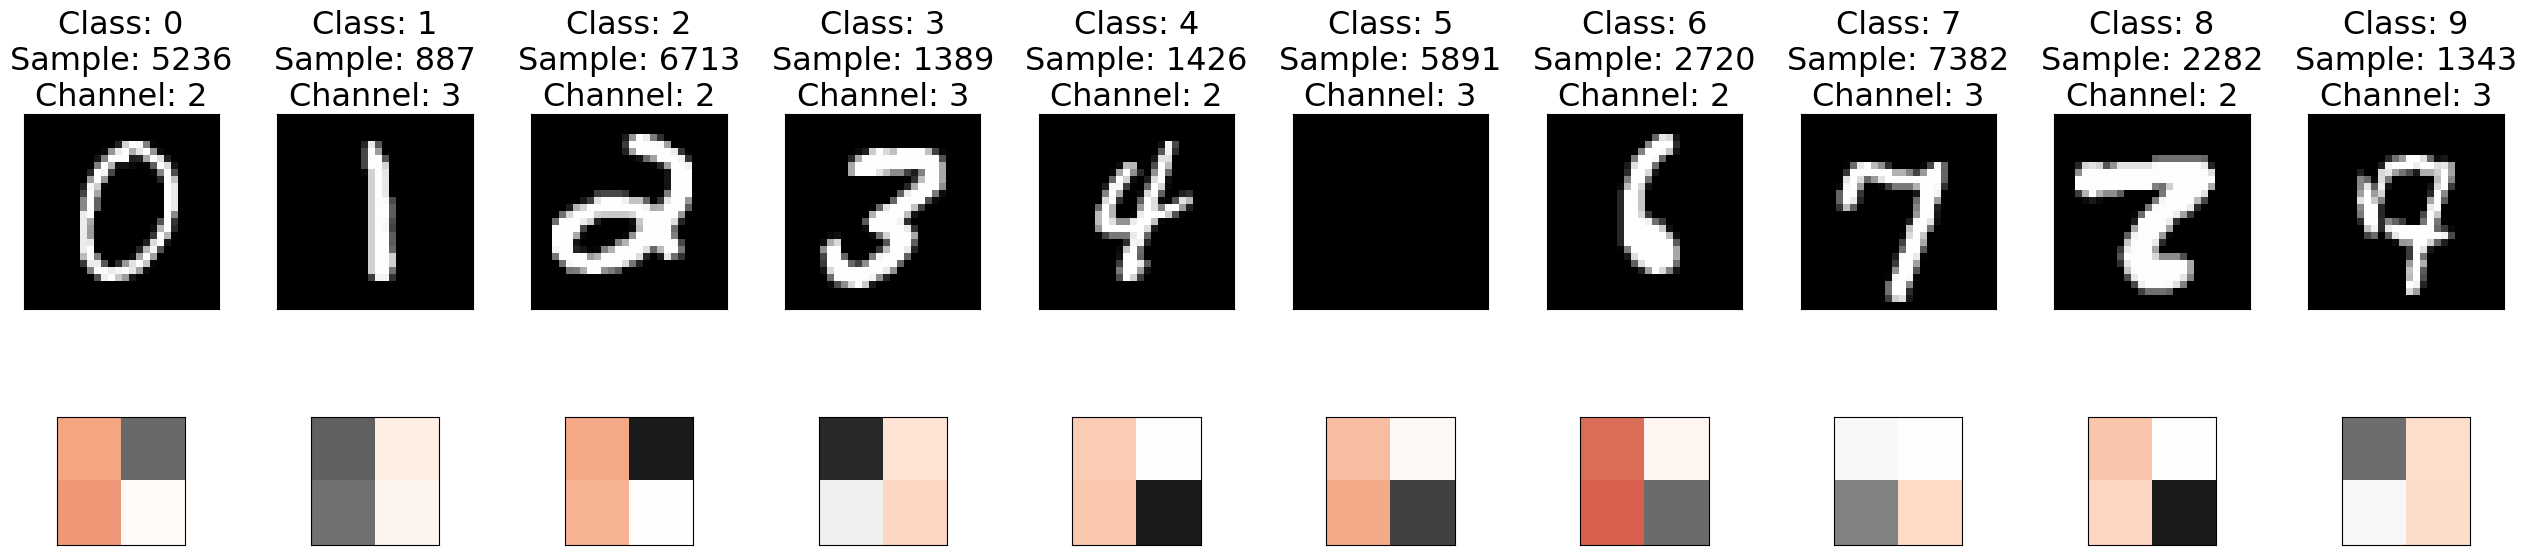

In [37]:
from collections import Counter
all_overall_prototype_winning_count = np.zeros((exp_var_dict['num_channels'],exp_var_dict['num_prototypes']))
correct_overall_prototype_winning_count = np.zeros((exp_var_dict['num_channels'],exp_var_dict['num_prototypes'])) 
correct1_overall_prototype_winning_count = np.zeros((exp_var_dict['num_channels'],exp_var_dict['num_prototypes'])) 
incorrect_overall_prototype_winning_count = np.zeros((exp_var_dict['num_channels'],exp_var_dict['num_prototypes']))

plt.style.use('default') 


fig, axs = plt.subplots(
    2, 10, figsize=(32,6),
    gridspec_kw={'height_ratios': [1, 0.5]} 
)

for class_label in range(0,10):
    score_avg1 = []
    score_avg2 = []
    proto_ind_count = []
    proto_ind_count2 = []
    label_avg = []
    label_avg1 = []
    label_avgs = []
    for q in range(len(test_images)):
        if correct[q] == 1 and pred_label[q] == class_label:
            pred_lab = pred_label[q]
            weights = whole.final_list[0].last_layer.weight.cpu().detach().numpy()
            sim_values = all_max_sims[q,:,:].reshape(exp_var_dict['num_channels']*exp_var_dict['num_prototypes'])
            scores = sim_values * weights[pred_lab,:] #scores for predicted prototype
                

            scores_sort = np.argsort(scores)
            ind1 = scores_sort[-1]
            ind2 = scores_sort[-2]
            score_avg1.append(scores[ind1]/sum(scores))
            score_avg2.append(scores[ind2]/sum(scores))
            chan_num = ind1 // exp_var_dict['num_prototypes']
            all_num = ind1 % exp_var_dict['num_prototypes']

            label_score_total = 0

            for score in scores_sort:
                chan_num1 = score // exp_var_dict['num_prototypes']
                all_num1 = score % exp_var_dict['num_prototypes']
                proto_ind1 = int(all_prototype_sample_ind[chan_num1][all_num1])
                if int(all_labels[proto_ind1]) == class_label:
                    label_score_total += scores[score]
            label_avg.append(label_score_total/sum(scores))

            result = scores.reshape(3, 10, 5).sum(axis=(0, 2))
            label_avg1.append(result[class_label]/sum(scores))
            label_avgs.append(result/sum(scores))




            proto_ind = int(all_prototype_sample_ind[chan_num][all_num])
            proto_ind_count.append(ind1)
            proto_ind_count2.append(ind2)
            if correct[q] == 1:
                correct_overall_prototype_winning_count[chan_num][all_num] += 1
                if int(all_labels[proto_ind]) == int(true_label[q]):
                    correct1_overall_prototype_winning_count[chan_num][all_num] += 1
            else:
                incorrect_overall_prototype_winning_count[chan_num][all_num] +=1

    ind = mode(proto_ind_count)
    ind_2 = mode(proto_ind_count2)

    freq_count = Counter(proto_ind_count)
    freq_count_2 = Counter(proto_ind_count2)

    sorted_freq_count = freq_count.most_common()
    sorted_freq_count_2 = freq_count_2.most_common()
    print(class_label)
    print(sorted_freq_count)
    print(sorted_freq_count_2)
    print(sum(score_avg1)/len(score_avg1))
    print(sum(score_avg2)/len(score_avg2))
    print(sum(label_avg)/len(label_avg))
    print(sum(label_avg1)/len(label_avg1))
    #print(np.mean(np.asarray(label_avgs),axis=0))

    chan_num = ind // exp_var_dict['num_prototypes']
    all_num = ind % exp_var_dict['num_prototypes']

    i3 = int(all_conv_prototypes[chan_num][all_num,0])
    j3 = int(all_conv_prototypes[chan_num][all_num,1])

    proto_ind = int(all_prototype_sample_ind[chan_num][all_num]) 
    input_mask, y1, y2, x1, x2 = output_to_input(i3,j3,chan_rf[chan_num][0], chan_rf[chan_num][1], chan_rf[chan_num][2], chan_rf[chan_num][3], input_size)

    xy = (x1, y1)
    rect = patches.Rectangle(xy , x2-x1, y2-y1, linewidth=1, edgecolor='r', facecolor='none')
    axs[0, class_label].set_xticks([])
    axs[0, class_label].set_yticks([])
    axs[0, class_label].set_title("Class: "+str(class_label)+"\nSample: " +str(proto_ind)+"\nChannel: "+str(chan_num+1), fontsize=23)

    row1 = 56 - y2  
    row2 = 56 - y1
    col1 = x1
    col2 = x2

    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2

    if cx < 28 and cy < 28:
        quadrant = 2 
    elif cx >= 28 and cy < 28:
        quadrant = 3  
    elif cx < 28 and cy >= 28:
        quadrant = 0  
    else:
        quadrant = 1  

    if quadrant == 0:      
        x_slice = slice(0, 28)
        y_slice = slice(0, 28)
    elif quadrant == 1:   
        x_slice = slice(0, 28)
        y_slice = slice(28, 56)
    elif quadrant == 2:     
        x_slice = slice(28, 56)
        y_slice = slice(0, 28)
    else:                  
        x_slice = slice(28, 56)
        y_slice = slice(28, 56)

    axs[0, class_label].imshow(all_images[proto_ind,chan_num,x_slice,y_slice], cmap='gray')
    axs[1, class_label].imshow( all_loc_scale[chan_num][all_num],vmin=-1, vmax=1,cmap='RdGy')
    axs[1, class_label].set_xticks([])
    axs[1, class_label].set_yticks([])

    ax = axs[1, class_label]
    pos = ax.get_position()  
    new_height = pos.height
    new_bottom = pos.y0 + (0.5 * (0.5 - new_height)) 
    ax.set_position([pos.x0, new_bottom, pos.width, new_height])
    plt.subplots_adjust(hspace=0.4, wspace=0.3)

plt.show()

#plt.savefig("mnist_figs/mnist_freqproto_crop.pdf", format="pdf",bbox_inches='tight')


0
[(93, 93), (50, 27), (60, 9)]
[(60, 98), (50, 23), (93, 8)]
0.22263544271456473
0.19948081270628784
0.34535655755980027
0.345356557636419
1
[(109, 110), (107, 9)]
[(57, 119)]
0.2646471581410905
0.10631672073356069
0.9580361369992757
0.9580361377197285
2
[(79, 91), (67, 21), (62, 6)]
[(62, 100), (79, 9), (54, 9)]
0.22948469660347548
0.19459695533438712
0.3694718914785478
0.36947189092537
3
[(126, 125)]
[(116, 83), (114, 42)]
0.22972518392906952
0.14270109890502516
0.5098805984711748
0.5098805963583489
4
[(83, 55), (73, 49)]
[(73, 55), (83, 49)]
0.14361145645047535
0.1284636483936994
0.8123123941515357
0.8123123954568909
5
[(123, 51), (149, 33), (127, 21), (129, 3), (147, 1)]
[(149, 62), (147, 21), (127, 18), (129, 5), (123, 3)]
0.1830869441051666
0.15930811820041113
0.2939291634346793
0.29392916316155593
6
[(81, 109)]
[(76, 109)]
0.2665528753626426
0.14315333580219736
0.6867171531888134
0.6867171506633957
7
[(122, 60), (112, 35), (115, 12), (117, 11)]
[(122, 40), (112, 37), (117, 33),

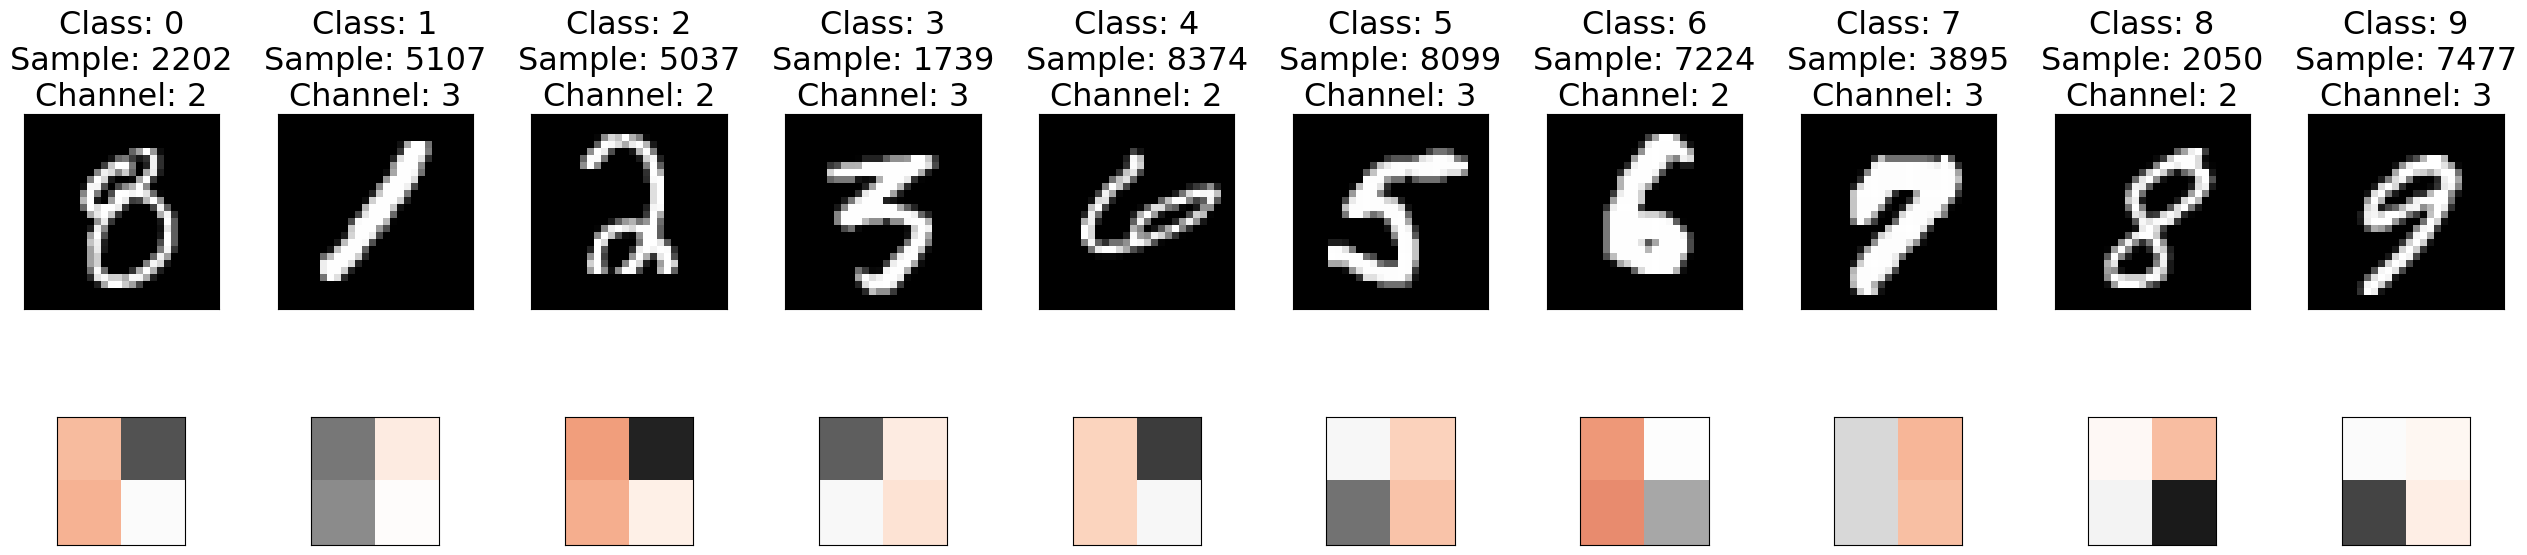

In [13]:
from collections import Counter
all_overall_prototype_winning_count = np.zeros((exp_var_dict['num_channels'],exp_var_dict['num_prototypes']))
correct_overall_prototype_winning_count = np.zeros((exp_var_dict['num_channels'],exp_var_dict['num_prototypes'])) 
correct1_overall_prototype_winning_count = np.zeros((exp_var_dict['num_channels'],exp_var_dict['num_prototypes'])) 
incorrect_overall_prototype_winning_count = np.zeros((exp_var_dict['num_channels'],exp_var_dict['num_prototypes']))

plt.style.use('default') 


fig, axs = plt.subplots(
    2, 10, figsize=(32,6),
    gridspec_kw={'height_ratios': [1, 0.5]} 
)

for class_label in range(0,10):
    score_avg1 = []
    score_avg2 = []
    proto_ind_count = []
    proto_ind_count2 = []
    label_avg = []
    label_avg1 = []
    label_avgs = []
    for q in range(len(test_images)):
        if correct[q] == 1 and pred_label[q] == class_label:
            pred_lab = pred_label[q]
            weights = whole.final_list[0].last_layer.weight.cpu().detach().numpy()
            sim_values = all_max_sims[q,:,:].reshape(exp_var_dict['num_channels']*exp_var_dict['num_prototypes'])
            scores = sim_values * weights[pred_lab,:] #scores for predicted prototype
                

            scores_sort = np.argsort(scores)
            ind1 = scores_sort[-2]
            ind2 = scores_sort[-3]
            score_avg1.append(scores[ind1]/sum(scores))
            score_avg2.append(scores[ind2]/sum(scores))
            chan_num = ind1 // exp_var_dict['num_prototypes']
            all_num = ind1 % exp_var_dict['num_prototypes']

            label_score_total = 0

            for score in scores_sort:
                chan_num1 = score // exp_var_dict['num_prototypes']
                all_num1 = score % exp_var_dict['num_prototypes']
                proto_ind1 = int(all_prototype_sample_ind[chan_num1][all_num1])
                if int(all_labels[proto_ind1]) == class_label:
                    label_score_total += scores[score]
            label_avg.append(label_score_total/sum(scores))

            result = scores.reshape(3, 10, 5).sum(axis=(0, 2))
            label_avg1.append(result[class_label]/sum(scores))
            label_avgs.append(result/sum(scores))




            proto_ind = int(all_prototype_sample_ind[chan_num][all_num])
            proto_ind_count.append(ind1)
            proto_ind_count2.append(ind2)
            if correct[q] == 1:
                correct_overall_prototype_winning_count[chan_num][all_num] += 1
                if int(all_labels[proto_ind]) == int(true_label[q]):
                    correct1_overall_prototype_winning_count[chan_num][all_num] += 1
            else:
                incorrect_overall_prototype_winning_count[chan_num][all_num] +=1

    ind = mode(proto_ind_count)
    ind_2 = mode(proto_ind_count2)

    freq_count = Counter(proto_ind_count)
    freq_count_2 = Counter(proto_ind_count2)

    sorted_freq_count = freq_count.most_common()
    sorted_freq_count_2 = freq_count_2.most_common()
    print(class_label)
    print(sorted_freq_count)
    print(sorted_freq_count_2)
    print(sum(score_avg1)/len(score_avg1))
    print(sum(score_avg2)/len(score_avg2))
    print(sum(label_avg)/len(label_avg))
    print(sum(label_avg1)/len(label_avg1))
    #print(np.mean(np.asarray(label_avgs),axis=0))

    chan_num = ind // exp_var_dict['num_prototypes']
    all_num = ind % exp_var_dict['num_prototypes']

    i3 = int(all_conv_prototypes[chan_num][all_num,0])
    j3 = int(all_conv_prototypes[chan_num][all_num,1])

    proto_ind = int(all_prototype_sample_ind[chan_num][all_num]) 
    input_mask, y1, y2, x1, x2 = output_to_input(i3,j3,chan_rf[chan_num][0], chan_rf[chan_num][1], chan_rf[chan_num][2], chan_rf[chan_num][3], input_size)

    xy = (x1, y1)
    rect = patches.Rectangle(xy , x2-x1, y2-y1, linewidth=1, edgecolor='r', facecolor='none')
    axs[0, class_label].set_xticks([])
    axs[0, class_label].set_yticks([])
    axs[0, class_label].set_title("Class: "+str(class_label)+"\nSample: " +str(proto_ind)+"\nChannel: "+str(chan_num+1), fontsize=23)

    row1 = 56 - y2  
    row2 = 56 - y1
    col1 = x1
    col2 = x2

    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2

    if cx < 28 and cy < 28:
        quadrant = 2 
    elif cx >= 28 and cy < 28:
        quadrant = 3  
    elif cx < 28 and cy >= 28:
        quadrant = 0  
    else:
        quadrant = 1  

    if quadrant == 0:      
        x_slice = slice(0, 28)
        y_slice = slice(0, 28)
    elif quadrant == 1:   
        x_slice = slice(0, 28)
        y_slice = slice(28, 56)
    elif quadrant == 2:     
        x_slice = slice(28, 56)
        y_slice = slice(0, 28)
    else:                  
        x_slice = slice(28, 56)
        y_slice = slice(28, 56)

    axs[0, class_label].imshow(all_images[proto_ind,chan_num,x_slice,y_slice], cmap='gray')
    axs[1, class_label].imshow( all_loc_scale[chan_num][all_num],vmin=-1, vmax=1,cmap='RdGy')
    axs[1, class_label].set_xticks([])
    axs[1, class_label].set_yticks([])

    ax = axs[1, class_label]
    pos = ax.get_position()  
    new_height = pos.height
    new_bottom = pos.y0 + (0.5 * (0.5 - new_height)) 
    ax.set_position([pos.x0, new_bottom, pos.width, new_height])
    plt.subplots_adjust(hspace=0.4, wspace=0.3)



#plt.savefig("mnist_freqproto2_crop.pdf", format="pdf",bbox_inches='tight')
plt.show()
